# Task 3: Short-Video Use and Academic Procrastination

This notebook demonstrates a reproducible analysis workflow using simulated records. The data are not real student survey responses. Questionnaire-style records have no timed warm-up phase, so warm-up filtering is not applicable to this adaptation.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

raw_path = ROOT / "data" / "raw" / "synthetic_student_survey.jsonl"
with raw_path.open("r", encoding="utf-8") as file:
    records = [json.loads(line) for line in file if line.strip()]

raw = pd.DataFrame(records)
print("Loaded records:", len(raw))
display(raw.head())

Loaded records: 120


,student_id,daily_video_hours,during_study,study_year,simulated_procrastination_score,data_type
0,S001,1.76,No,4,1.53,synthetic_simulation
1,S002,0.69,No,4,2.56,synthetic_simulation
2,S003,2.40,No,3,2.39,synthetic_simulation
3,S004,2.74,Yes,2,3.16,synthetic_simulation
4,S005,0.36,No,4,2.02,synthetic_simulation


In [2]:
initial_count = len(raw)
data = raw.drop_duplicates(subset="student_id").copy()

data["daily_video_hours"] = pd.to_numeric(
    data["daily_video_hours"], errors="coerce"
)
data["simulated_procrastination_score"] = pd.to_numeric(
    data["simulated_procrastination_score"], errors="coerce"
)

valid = (
    data["daily_video_hours"].between(0, 24)
    & data["simulated_procrastination_score"].between(1, 5)
    & data["during_study"].isin(["Yes", "No"])
)
clean = data.loc[valid].copy()

clean["consumption_group"] = pd.cut(
    clean["daily_video_hours"],
    bins=[-np.inf, 1, 3, np.inf],
    labels=["Baseline (<=1 h/day)", "Middle (1-3 h/day)", "Heavy (>3 h/day)"],
)

print("Records loaded:", initial_count)
print("Duplicates removed:", initial_count - len(data))
print("Invalid records removed:", len(data) - len(clean))
print("Records analyzed:", len(clean))
print("Warm-up filtering: not applicable to this survey-style dataset.")

Records loaded: 120
Duplicates removed: 0
Invalid records removed: 0
Records analyzed: 120
Warm-up filtering: not applicable to this survey-style dataset.


In [3]:
def bootstrap_mean_ci(values, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    means = [
        rng.choice(values, size=len(values), replace=True).mean()
        for _ in range(n_boot)
    ]
    return np.quantile(means, [0.025, 0.975])


rows = []
for name, group in clean.groupby("consumption_group", observed=True):
    scores = group["simulated_procrastination_score"].to_numpy()
    ci_low, ci_high = bootstrap_mean_ci(scores)

    rows.append({
        "group": str(name),
        "n": len(scores),
        "mean": scores.mean(),
        "median": np.median(scores),
        "25th_percentile": np.quantile(scores, 0.25),
        "75th_percentile": np.quantile(scores, 0.75),
        "bootstrap_CI_low": ci_low,
        "bootstrap_CI_high": ci_high,
    })

summary = pd.DataFrame(rows)
display(summary.round(3))

,group,n,mean,median,25th_percentile,75th_percentile,bootstrap_CI_low,bootstrap_CI_high
0,Baseline (<=1 h/day),32,2.741,2.705,2.245,3.162,2.487,2.997
1,Middle (1-3 h/day),81,3.104,3.100,2.580,3.580,2.956,3.254
2,Heavy (>3 h/day),7,3.419,3.550,3.150,3.900,2.745,3.981


In [4]:
correlation, correlation_p = stats.pearsonr(
    clean["daily_video_hours"],
    clean["simulated_procrastination_score"],
)

baseline = clean.loc[
    clean["daily_video_hours"] <= 1,
    "simulated_procrastination_score",
]
heavy = clean.loc[
    clean["daily_video_hours"] > 3,
    "simulated_procrastination_score",
]

welch_t, welch_p = stats.ttest_ind(heavy, baseline, equal_var=False)

print(f"Pearson correlation: r = {correlation:.3f}, p = {correlation_p:.4f}")
print(f"Welch test, heavy vs baseline: t = {welch_t:.3f}, p = {welch_p:.4f}")
print("These results describe simulated data only.")

Pearson correlation: r = 0.308, p = 0.0006
Welch test, heavy vs baseline: t = 1.868, p = 0.0990
These results describe simulated data only.


Figures saved as PNG (300 DPI) and PDF in reports/figures/
Reminder: the figures use simulated data.


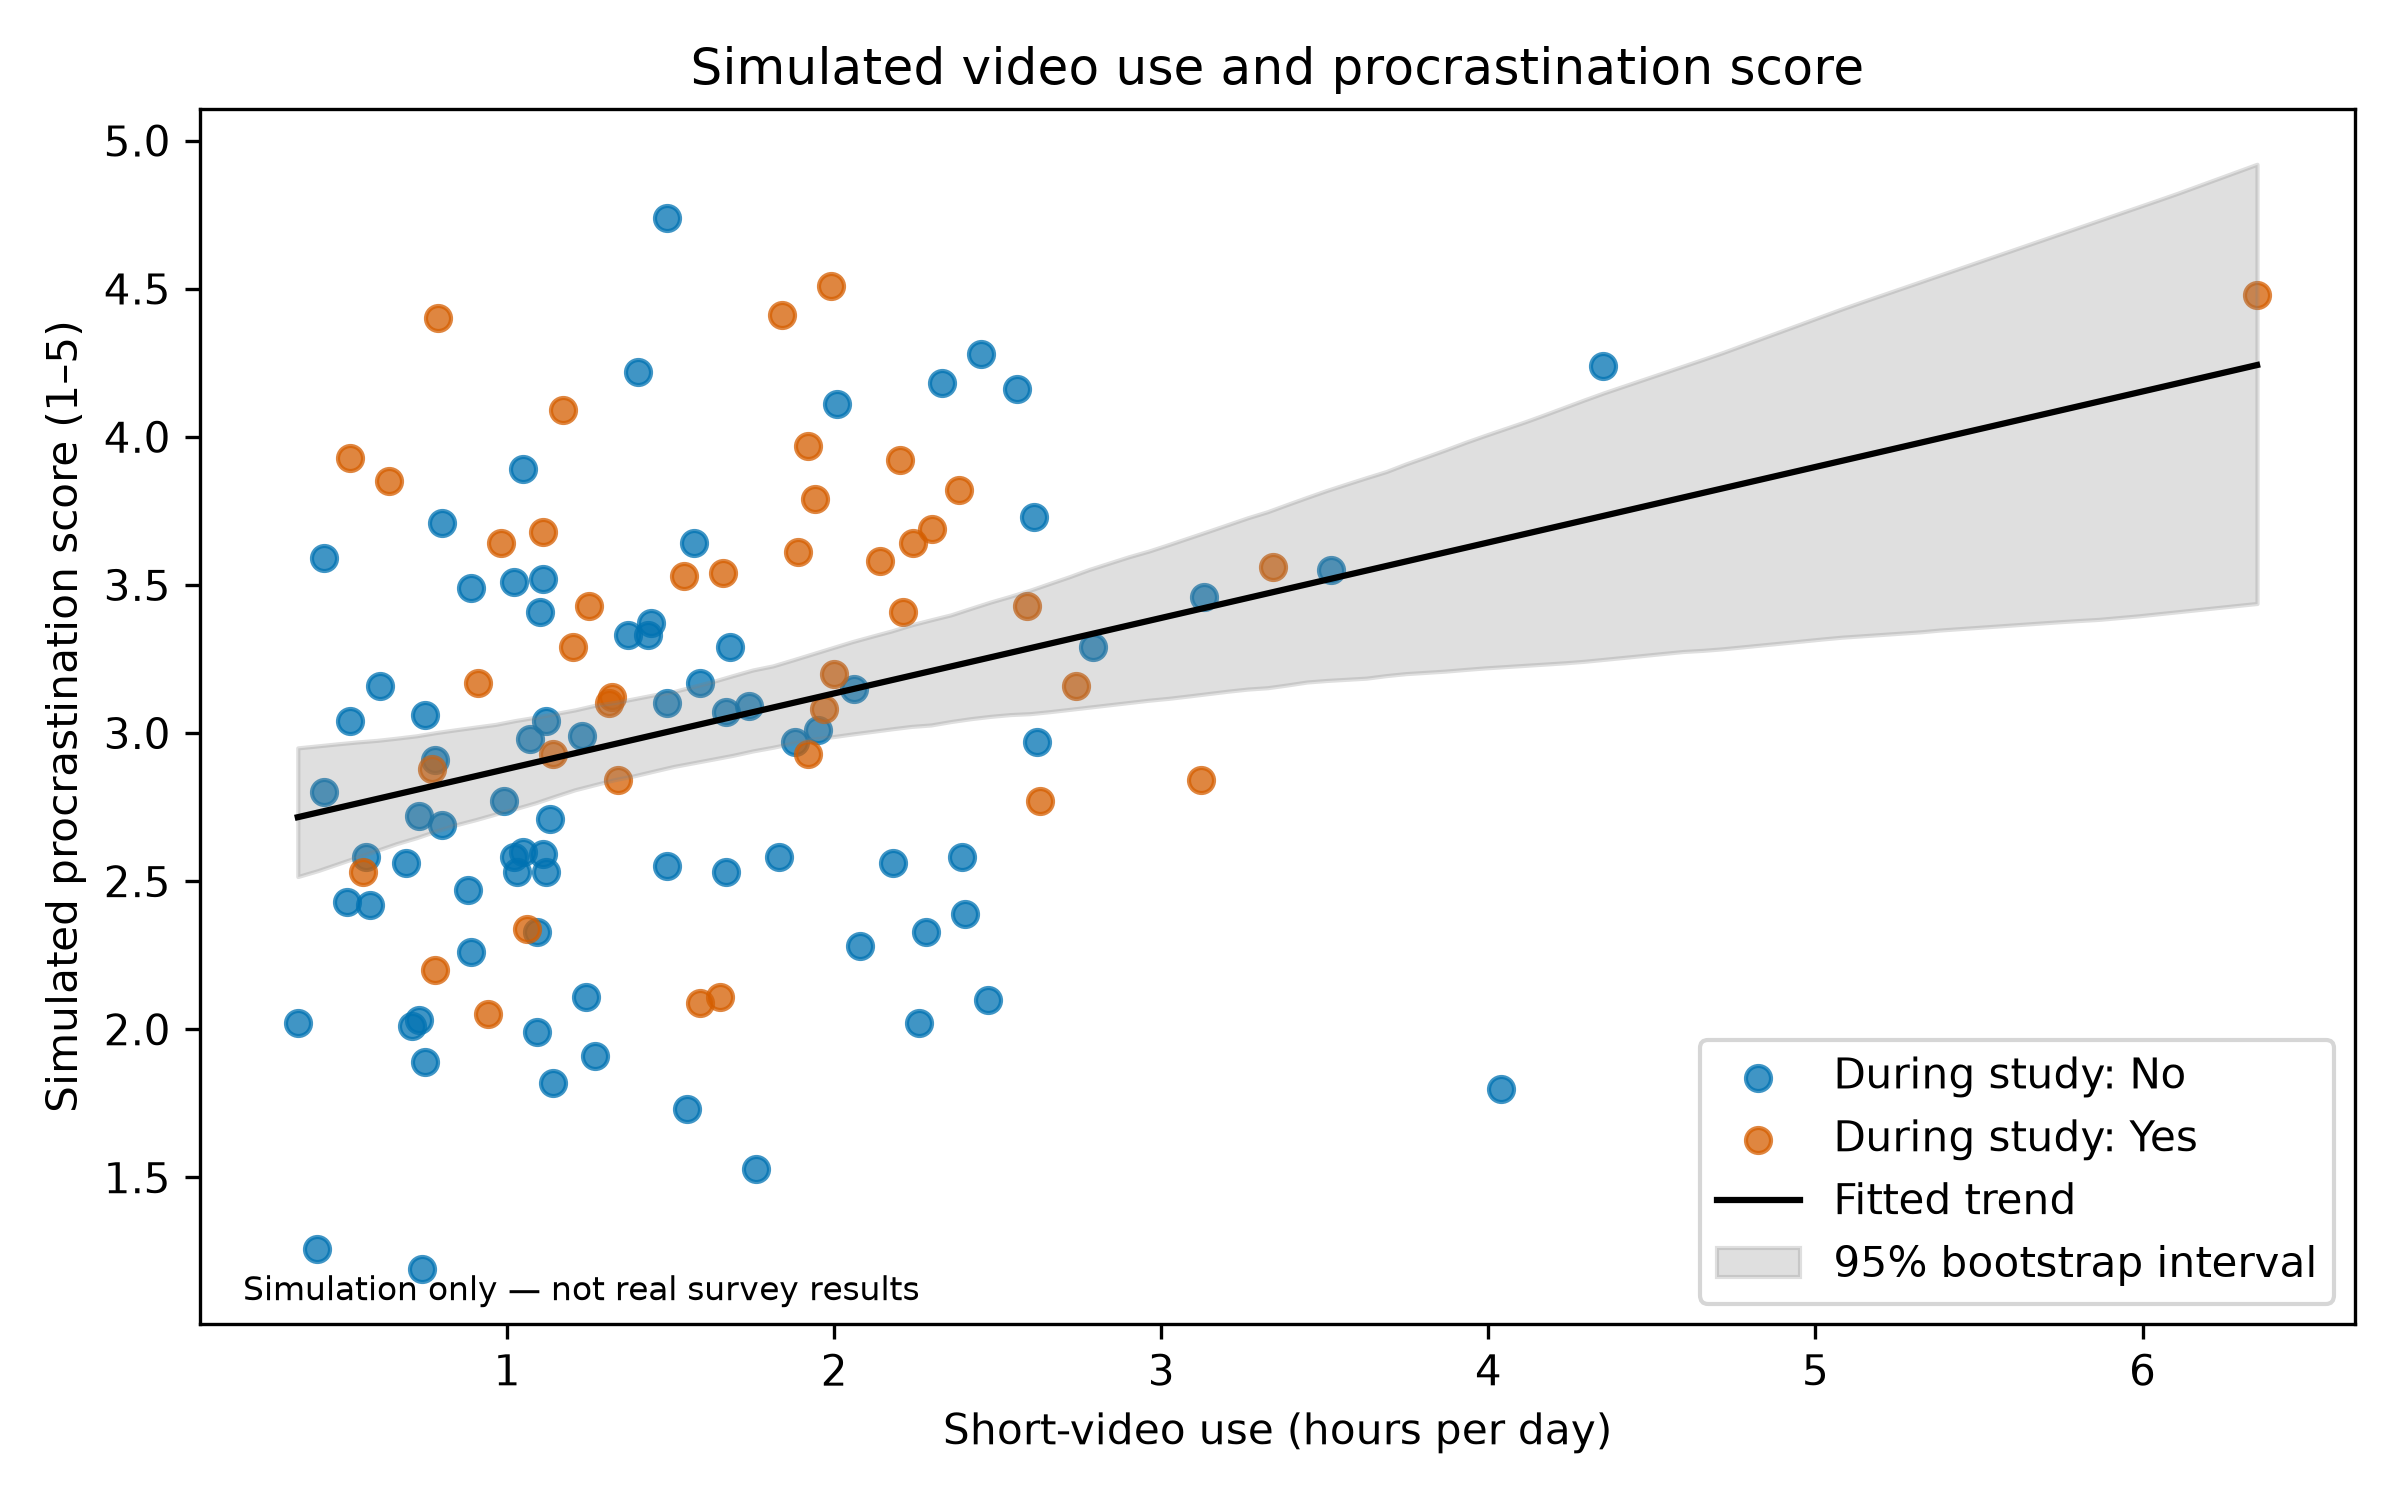

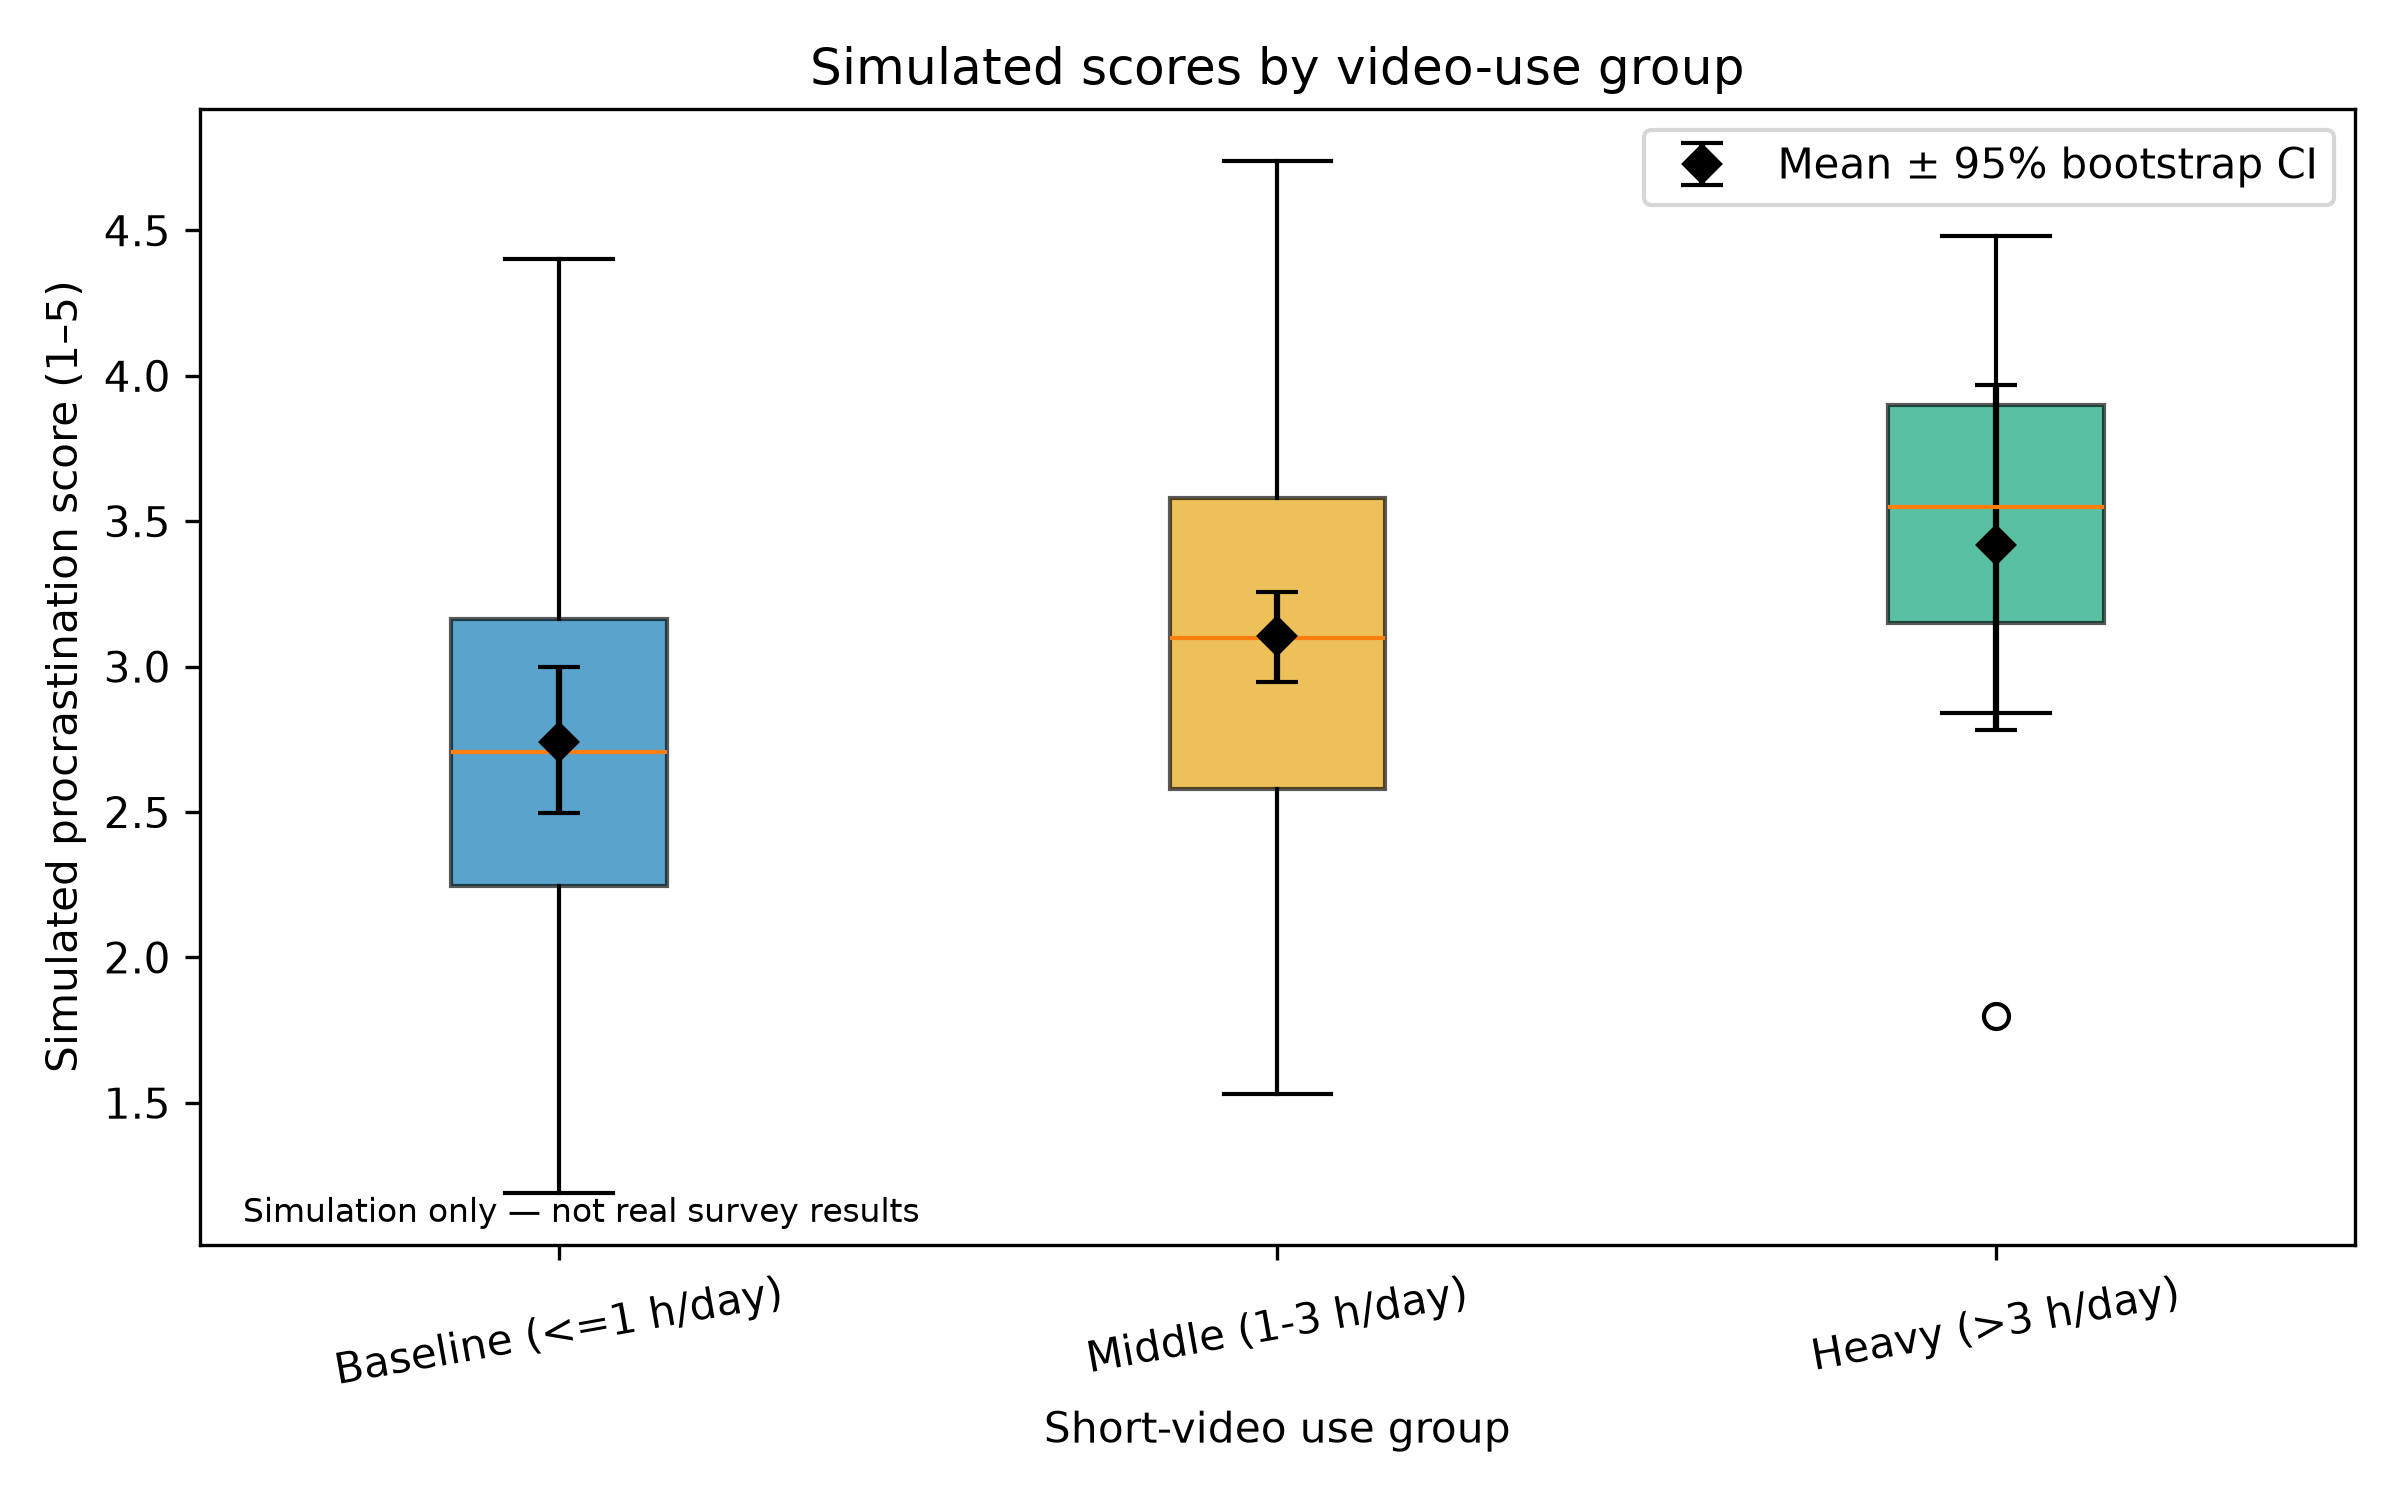

In [5]:
import subprocess
import sys
from IPython.display import Image, display

visualize_script = ROOT / "src" / "visualize.py"
subprocess.run([sys.executable, str(visualize_script)], check=True)

display(Image(filename=str(ROOT / "reports" / "figures" / "video_hours_vs_score.png")))
display(Image(filename=str(ROOT / "reports" / "figures" / "score_by_video_group.png")))